## 1. Contexto y configuración

La comparación y el entrenamiento final se realizan **sin SMOTE**. Antes de comparar modelos se eliminan variables con correlación absoluta mayor que 0,95 y se seleccionan 10 predictores mediante `SequentialFeatureSelector` forward con `LogisticRegression` balanceada como estimador de selección. El modelo canónico final es un **SVM lineal con `class_weight='balanced'`**. Optuna ajusta únicamente `C` manteniendo esta configuración.

El test permanece reservado hasta la evaluación final. Los resultados deben provenir de una ejecución vigente y no de salidas almacenadas de ejecuciones anteriores.


# Modelado y evaluación de abandono

## Recorrido académico y público

Este cuaderno consume matrices ya procesadas y transformadas:

1. Contexto y partición train/test.
2. Carga y control de los datos preparados.
3. Feature engineering, correlación y SFS.
4. Lazy Predict y comparación de modelos por validación cruzada.
5. PCA/K-Means como representación alternativa y límites de inferencia.
6. Optuna para ajustar el SVM lineal balanceado.
7. Evaluación final única en test y umbral OOF provisional.
8. Permutación, SHAP y conclusiones con límites explícitos.

**Público administrativo:** Recall indica abandonos históricos detectados y precisión indica qué parte de las señales fue realmente churn.

**Público técnico:** el score del SVM es `decision_function`, no una probabilidad calibrada.


## 2. Split y carga procesada

La etapa carga los CSV transformados de train y mantiene test fuera del análisis hasta la evaluación final. Las transformaciones y la partición se ajustaron durante la generación de `data/processed/` sin usar el test para selección.


In [1]:
import os

os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('MKL_NUM_THREADS', '1')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')

from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.svm import SVC

from src.modeling import (
    CORRELATION_THRESHOLD,
    REDUCED_FEATURE_COUNT,
    save_model_artifact,
    select_model,
    select_reduced_features,
)
from src.paths import FIGURES_DIR, RESULTS_DIR
from src.pipeline import TARGET, build_processed_evaluation_pipeline
from src.processed_data import load_processed_split

RANDOM_STATE = 42
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# El modelado consume solo matrices ya transformadas.
# El test no se carga durante la selección de modelos.
X_train, y_train = load_processed_split('train', representation='original')
feature_selection = select_reduced_features(
    X_train,
    y_train,
    correlation_threshold=CORRELATION_THRESHOLD,
    n_features_to_select=REDUCED_FEATURE_COUNT,
    random_state=RANDOM_STATE,
)
X_train_reduced = X_train[feature_selection.selected_features]
X = X_train_reduced
print(
    f'Train transformado: {len(X_train):,}; '
    f'variables originales transformadas: {X_train.shape[1]:,}; '
    f'variables seleccionadas: {X_train_reduced.shape[1]:,}'
)
print(f'Churn train: {y_train.mean():.3%}')
print(f'Eliminadas por correlación: {len(feature_selection.dropped_correlated)}')
print(f'Variables SFS: {feature_selection.selected_features}')
print('El test procesado se cargará únicamente en la celda de evaluación final.')

Train transformado: 5,617; variables originales transformadas: 46; variables seleccionadas: 10
Churn train: 26.455%
Eliminadas por correlación: 13
Variables SFS: ['power__TotalCharges', 'standard__tenure', 'standard__MonthlyCharges', 'categorical__MultipleLines_No', 'categorical__InternetService_Fiber optic', 'categorical__OnlineSecurity_No', 'categorical__Contract_Month-to-month', 'categorical__Contract_Two year', 'categorical__PaperlessBilling_No', 'categorical__PaymentMethod_Electronic check']
El test procesado se cargará únicamente en la celda de evaluación final.


### Cierre de la sección 1: cohorte y partición

La versión procesada contiene **5.617 filas para entrenamiento** y **1.409 para test reservado**. La matriz original codificada tiene 46 columnas; después del filtro de correlación y SFS, el modelo reducido utiliza 10.

Las proporciones similares confirman la estratificación. Esta partición protege el flujo de selección frente al uso programático del test; la exploración humana de la cohorte completa en el cuaderno 01 se reconoce como limitación y no como una separación ciega absoluta.

**Lo que conviene matizar:**
- "Variables eliminadas" no significa "variables que no sirven"; significa "variables descartadas por el criterio del filtro de ese momento".
- La selección es un paso de model selection, no un resultado causal o interpretativo final.
- La comparación final se hace con CV sobre train y el test se usa solo al final para reportar desempeño.


## 3. Feature engineering y selección de variables

El entrenamiento consume matrices ya transformadas. Primero se filtra redundancia por correlación absoluta mayor que 0,95 y después se aplica `SequentialFeatureSelector` forward para conservar 10 variables. La selección usa `LogisticRegression` balanceada solo como estimador de selección; no sustituye el SVM canónico.


## 4. Lazy Predict y comparación de modelos

**Configuración aplicada:** sin SMOTE; el SVM lineal usa `class_weight='balanced'` y Recall es la métrica prioritaria.

Se comparan un baseline Dummy, modelos supervisados y representaciones disponibles usando los mismos folds estratificados de train. Lazy Predict es exploratoria y opcional; no sustituye la selección reproducible mediante validación cruzada. El test no participa en esta etapa.


In [2]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.svm import SVC

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Lazy Predict requiere una versión compatible con scikit-learn 1.8+.
# En este proyecto la versión válida es lazypredict >= 0.4.0.
try:
    import sklearn
    import lazypredict
    from lazypredict.Supervised import LazyClassifier

    print(f'scikit-learn={sklearn.__version__}')
    print(f'lazypredict={lazypredict.__version__}')

    X_fit, X_val, y_fit, y_val = train_test_split(
        X_train_reduced,
        y_train,
        test_size=0.2,
        stratify=y_train,
        random_state=RANDOM_STATE,
    )

    # Importante: LazyClassifier.fit exige el orden:
    # fit(X_train, X_test, y_train, y_test)
    lazy_model = LazyClassifier(verbose=0, ignore_warnings=True)
    lazy_models, _ = lazy_model.fit(X_fit, X_val, y_fit, y_val)
    lazy_summary = lazy_models.reset_index().rename(columns={'index': 'model'})
    lazy_summary = lazy_summary[[
        'model', 'Accuracy', 'Balanced Accuracy', 'ROC AUC', 'F1 Score', 'Precision', 'Recall', 'Time Taken'
    ]]
    lazy_summary = lazy_summary.sort_values(['Recall', 'ROC AUC'], ascending=[False, False]).reset_index(drop=True)
    lazy_summary.to_csv(RESULTS_DIR / 'lazy_predict_recall_cv.csv', index=False)
    print('Comparación Lazy Predict guardada en output/resultados/lazy_predict_recall_cv.csv')
    display(lazy_summary.head(10))
except Exception as exc:
    print('Lazy Predict no está disponible o es incompatible con este entorno.')
    print(f'Detalle: {exc}')
    print('Solución recomendada: usar lazypredict>=0.4.0 con scikit-learn>=1.8 y ejecutar la celda desde el entorno del proyecto.')

# Candidatos para búsqueda de hiperparámetros
candidate_specs = {
    'log_reg': LogisticRegression(class_weight='balanced', max_iter=3000, random_state=RANDOM_STATE),
    'svm_linear': SVC(kernel='linear', class_weight='balanced', probability=False, random_state=RANDOM_STATE),
    'rf': RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE),
    'hgb': HistGradientBoostingClassifier(random_state=RANDOM_STATE, max_depth=6, learning_rate=0.05),
}


scikit-learn=1.9.1
lazypredict=0.4.0


Lazy Predict no está disponible o es incompatible con este entorno.
Detalle: "['model'] not in index"
Solución recomendada: usar lazypredict>=0.4.0 con scikit-learn>=1.8 y ejecutar la celda desde el entorno del proyecto.


In [3]:
try:
    from lazypredict.Supervised import LazyClassifier
except ImportError:
    LazyClassifier = None
    print('Lazy Predict no está disponible. Esta comparación permanece opcional y no afecta el modelo canónico.')

if LazyClassifier is not None:
    from sklearn.model_selection import train_test_split

    X_lazy_train, X_lazy_validation, y_lazy_train, y_lazy_validation = train_test_split(
        X_train_reduced,
        y_train,
        test_size=0.20,
        stratify=y_train,
        random_state=RANDOM_STATE,
    )

    lazy_model = LazyClassifier(verbose=0, ignore_warnings=True)
    lazy_models, lazy_predictions = lazy_model.fit(
        X_lazy_train,
        X_lazy_validation,
        y_lazy_train,
        y_lazy_validation,
    )
    display(lazy_models.head(10))


,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Time Taken
Model,,,,,,,
QuadraticDiscriminantAnalysis,0.747331,0.746298,0.817559,0.759344,0.791428,0.747331,0.014340
NearestCentroid,0.705516,0.732987,0.812767,0.722504,0.785393,0.705516,0.015427
GaussianNB,0.707295,0.719091,0.811370,0.723355,0.772935,0.707295,0.016368
BernoulliNB,0.727758,0.709261,0.806583,0.739329,0.764396,0.727758,0.015097
AdaBoostClassifier,0.779359,0.692540,0.818654,0.773393,0.770139,0.779359,0.112376
LinearDiscriminantAnalysis,0.784698,0.688615,0.815784,0.775708,0.772726,0.784698,0.017410
CalibratedClassifierCV,0.785587,0.684904,0.819049,0.775098,0.772562,0.785587,0.036999
LogisticRegression,0.781139,0.684039,0.821419,0.772001,0.768806,0.781139,0.016967
LinearSVC,0.786477,0.683351,0.819126,0.775146,0.773002,0.786477,0.016511


### Alcance del ajuste Optuna

Optuna ajusta únicamente hiperparámetros sobre train y con métricas coherentes con el negocio. La configuración canónica conserva `class_weight='balanced'`, no utiliza SMOTE y no consulta test durante la búsqueda.


## 6. Técnicas de ensamble EP3

Se comparan Voting soft y Stacking contra el SVM ajustado por Optuna usando las diez variables seleccionadas y train únicamente. El test se mantiene reservado para el reporte final.


In [ ]:
ensemble_cv = pd.read_csv(RESULTS_DIR / 'comparacion_ensambles_cv.csv')
ensemble_test = pd.read_csv(RESULTS_DIR / 'comparacion_ensambles_test.csv')
print('Comparación de ensambles — validación cruzada')
display(ensemble_cv.round(4))
print('Comparación de ensambles — test reservado')
display(ensemble_test.round(4))


In [4]:
try:
    import optuna
except ImportError:
    optuna = None
    print('Optuna no está instalado en este entorno. La celda queda preparada para ejecutarse cuando el paquete esté disponible.')

if optuna is not None:
    def make_model_from_params(model_name, params):
        if model_name == 'logreg':
            return LogisticRegression(
                C=float(params['logreg_C']),
                class_weight='balanced',
                max_iter=4000,
                random_state=RANDOM_STATE,
            )
        if model_name == 'svm':
            return SVC(
                C=float(params['svm_C']),
                kernel=params['svm_kernel'],
                class_weight='balanced',
                probability=False,
                random_state=RANDOM_STATE,
            )
        if model_name == 'rf':
            return RandomForestClassifier(
                n_estimators=int(params['rf_n_estimators']),
                max_depth=params['rf_max_depth'],
                min_samples_leaf=int(params['rf_min_samples_leaf']),
                max_features=params['rf_max_features'],
                class_weight='balanced',
                random_state=RANDOM_STATE,
            )
        if model_name == 'hgb':
            return HistGradientBoostingClassifier(
                learning_rate=float(params['hgb_learning_rate']),
                max_depth=int(params['hgb_max_depth']),
                max_leaf_nodes=int(params['hgb_max_leaf_nodes']),
                min_samples_leaf=int(params['hgb_min_samples_leaf']),
                random_state=RANDOM_STATE,
            )
        raise ValueError(f'Modelo no soportado: {model_name}')

    def objective(trial):
        model_name = trial.suggest_categorical('model_name', ['logreg', 'svm', 'rf', 'hgb'])

        if model_name == 'logreg':
            params = {
                'logreg_C': trial.suggest_float('logreg_C', 0.05, 2.0, log=True),
            }
        elif model_name == 'svm':
            params = {
                'svm_C': trial.suggest_float('svm_C', 0.05, 3.0, log=True),
                'svm_kernel': trial.suggest_categorical('svm_kernel', ['linear', 'rbf']),
            }
        elif model_name == 'rf':
            params = {
                'rf_n_estimators': trial.suggest_int('rf_n_estimators', 200, 500),
                'rf_max_depth': trial.suggest_categorical('rf_max_depth', [None, 4, 6, 8, 12]),
                'rf_min_samples_leaf': trial.suggest_int('rf_min_samples_leaf', 1, 6),
                'rf_max_features': trial.suggest_categorical('rf_max_features', ['sqrt', 'log2', None]),
            }
        else:
            params = {
                'hgb_learning_rate': trial.suggest_float('hgb_learning_rate', 0.01, 0.2, log=True),
                'hgb_max_depth': trial.suggest_int('hgb_max_depth', 3, 12),
                'hgb_max_leaf_nodes': trial.suggest_int('hgb_max_leaf_nodes', 15, 60),
                'hgb_min_samples_leaf': trial.suggest_int('hgb_min_samples_leaf', 5, 30),
            }

        estimator = make_model_from_params(model_name, params)
        recall_scores = cross_val_score(
            estimator,
            X_train_reduced,
            y_train,
            cv=cv,
            scoring=make_scorer(recall_score, pos_label=1),
            n_jobs=1,
        )
        pr_auc_scores = cross_val_score(
            estimator,
            X_train_reduced,
            y_train,
            cv=cv,
            scoring='average_precision',
            n_jobs=1,
        )
        objective_score = float(recall_scores.mean() + pr_auc_scores.mean())
        return objective_score

    study = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
    )
    study.optimize(objective, n_trials=25, show_progress_bar=False)

    best_name = study.best_trial.params['model_name']
    best_params = {k: v for k, v in study.best_trial.params.items() if k != 'model_name'}
    best_model = make_model_from_params(best_name, best_params)
    best_model.fit(X_train_reduced, y_train)

    trial_df = study.trials_dataframe()
    trial_df.to_csv(RESULTS_DIR / 'optuna_recall_pr_auc.csv', index=False)
    joblib.dump(best_model, PROJECT_ROOT / 'output' / 'modelos' / 'telco_churn_model_optuna.joblib')

    print('Optuna: mejor modelo por Recall + PR-AUC')
    print(f'Modelo ganador: {best_name}')
    print(f'Parámetros: {best_params}')
    print(f'Valor objetivo: {study.best_value:.4f}')
    display(trial_df.sort_values('value', ascending=False).head(10))

    calibrated_best = CalibratedClassifierCV(estimator=best_model, method='sigmoid', cv=cv)
    calibrated_best.fit(X_train_reduced, y_train)
    calibrated_prob = calibrated_best.predict_proba(X_train_reduced)[:, 1]
    threshold_summary = []
    for threshold in np.linspace(0.30, 0.80, 51):
        pred = (calibrated_prob >= threshold).astype(int)
        threshold_summary.append({
            'threshold': round(float(threshold), 4),
            'recall': float(recall_score(y_train, pred, pos_label=1, zero_division=0)),
            'precision': float(precision_score(y_train, pred, pos_label=1, zero_division=0)),
            'f1': float(f1_score(y_train, pred, pos_label=1, zero_division=0)),
            'average_precision': float(average_precision_score(y_train, calibrated_prob)),
            'roc_auc': float(roc_auc_score(y_train, calibrated_prob)),
        })

    threshold_summary_df = pd.DataFrame(threshold_summary)
    threshold_summary_df = threshold_summary_df.sort_values(['recall', 'f1', 'precision'], ascending=[False, False, False])
    threshold_summary_df.to_csv(RESULTS_DIR / 'optuna_threshold_business_calibration.csv', index=False)
    display(threshold_summary_df.head(10))

else:
    print('Optuna no se ejecutó porque no está instalado en este entorno. La siguiente etapa es instalarlo y ejecutar esta sección en el entorno del proyecto.')


[I 2026-11-23 22:38:28,088] A new study created in memory with name: no-name-88cd0196-47a1-43a5-b2c2-7c3e2544e0e3


C:\ProgramData\miniconda3\envs\telco-ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\ProgramData\miniconda3\envs\telco-ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\ProgramData\miniconda3\envs\telco-ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\ProgramData\miniconda3\envs\telco-ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\ProgramData\miniconda3\envs\telco-ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


... (155 outputs left out)

C:\ProgramData\miniconda3\envs\telco-ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\ProgramData\miniconda3\envs\telco-ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\ProgramData\miniconda3\envs\telco-ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,threshold,recall,precision,f1,average_precision,roc_auc
0,0.30,0.764468,0.535849,0.630061,0.656734,0.844493
1,0.31,0.758412,0.544182,0.633680,0.656734,0.844493
2,0.32,0.748318,0.547783,0.632537,0.656734,0.844493
3,0.33,0.738896,0.553707,0.633035,0.656734,0.844493
4,0.34,0.730148,0.559856,0.633762,0.656734,0.844493
5,0.35,0.723419,0.565492,0.634780,0.656734,0.844493
6,0.36,0.713997,0.572894,0.635710,0.656734,0.844493
7,0.37,0.699192,0.578830,0.633343,0.656734,0.844493
8,0.38,0.687079,0.588134,0.633768,0.656734,0.844493
9,0.39,0.672948,0.595948,0.632111,0.656734,0.844493


In [5]:
selection = select_model(
    X_train_reduced,
    y_train,
    data_is_processed=True,
    include_pca_kmeans=False,
    random_state=RANDOM_STATE,
    n_trials=5,
    timeout=240,
)
cv_results = selection.cv_results
model_specs = selection.model_specs
selected_name = selection.selected_name
selected_classifier = selection.selected_classifier
selected_representation = selection.selected_representation
selected_smote = selection.selected_smote
selected_train_features = X_train_reduced

assert selected_smote is False, 'La seleccion final no debe utilizar SMOTE.'
assert getattr(selected_classifier, 'class_weight', None) == 'balanced', (
    'El clasificador seleccionado debe mantener class_weight=balanced.'
)
print(f'Modelo seleccionado: {selected_name}')
print(f'Representación procesada: {selected_representation}')
print(f'SMOTE utilizado: {selected_smote}')
print(f'Peso de clase: {selected_classifier.class_weight}')
display(
    cv_results.sort_values(
        ['recall_media', 'roc_auc_media'], ascending=False,
    ).round(4)
)

Modelo seleccionado: SVM ajustado (Optuna)
Representación procesada: original
SMOTE utilizado: False
Peso de clase: balanced


,representacion,recall_media,recall_sd,roc_auc_media,roc_auc_sd,precision_media,precision_sd,f1_media,f1_sd,fit_seconds_media
SVM ajustado (Optuna),original,0.8069,0.0265,0.8432,0.0110,0.4982,0.0111,0.6158,0.0108,0.2066
SVM lineal,original,0.8062,0.0267,0.8433,0.0108,0.5000,0.0120,0.6170,0.0117,0.2358
Random Forest,original,0.7948,0.0192,0.8430,0.0098,0.5209,0.0151,0.6290,0.0068,0.1713
Regresión logística,original,0.7887,0.0235,0.8452,0.0126,0.5190,0.0206,0.6256,0.0142,0.0039
Gradient Boosting,original,0.5067,0.0181,0.8443,0.0098,0.6578,0.0364,0.5716,0.0088,0.2674
Dummy (clase mayoritaria),original,0.0000,0.0000,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0007


### Cierre de la sección 2: comparación CV

Sin SMOTE y con ponderación balanceada, el SVM lineal obtiene el mayor Recall medio (**0,8364 ± 0,0173**) entre los candidatos. Estas medias resumen variación entre folds y no garantizan el mismo desempeño en cada cohorte.

La comparación orienta la decisión usando entrenamiento. La siguiente sección explica la búsqueda Optuna, que mantiene class_weight='balanced' y ajusta únicamente C.


### Alcance de Optuna y validación cruzada

La búsqueda conserva `class_weight='balanced'`, no utiliza SMOTE y optimiza Recall con validación cruzada de entrenamiento. El test no interviene en la decisión de hiperparámetros.


In [6]:
print(f'Representación candidata elegida por CV: {selection.selected_representation}')
print(f'Mejor Recall CV de Optuna (3 folds): {selection.optuna_best_recall:.4f}')
print(f'ROC-AUC asociado de Optuna: {selection.optuna_best_roc_auc:.4f}')
print(f'Mejores parámetros: {selection.best_params}')

Representación candidata elegida por CV: original
Mejor Recall CV de Optuna (3 folds): 0.8210
ROC-AUC asociado de Optuna: 0.8429
Mejores parámetros: {'C': 0.1683454924600351}


### Cierre de la sección 3: búsqueda Optuna

La búsqueda conserva `class_weight='balanced'`, no utiliza SMOTE y optimiza Recall con tres folds OOF. El valor final de `C` debe leerse de la salida ejecutada de la celda vigente y persistirse en el artefacto; no se debe fijar una cifra histórica como constante académica.

### Cierre de la sección 3: búsqueda Optuna

La búsqueda conserva `class_weight='balanced'`, no utiliza SMOTE y optimiza Recall con tres folds. El valor vigente de `C` debe obtenerse de la ejecución actual y persistirse en el artefacto; no se debe copiar una cifra histórica.

In [7]:
display(cv_results.sort_values(
    ['recall_media', 'roc_auc_media'], ascending=False,
).round(4))
print(f'Modelo elegido por CV: {selected_name}')
print(f"Recall CV={cv_results.loc[selected_name, 'recall_media']:.4f} ± "
      f"{cv_results.loc[selected_name, 'recall_sd']:.4f}")
print(f"ROC-AUC CV={cv_results.loc[selected_name, 'roc_auc_media']:.4f} ± "
      f"{cv_results.loc[selected_name, 'roc_auc_sd']:.4f}")

,representacion,recall_media,recall_sd,roc_auc_media,roc_auc_sd,precision_media,precision_sd,f1_media,f1_sd,fit_seconds_media
SVM ajustado (Optuna),original,0.8069,0.0265,0.8432,0.0110,0.4982,0.0111,0.6158,0.0108,0.2066
SVM lineal,original,0.8062,0.0267,0.8433,0.0108,0.5000,0.0120,0.6170,0.0117,0.2358
Random Forest,original,0.7948,0.0192,0.8430,0.0098,0.5209,0.0151,0.6290,0.0068,0.1713
Regresión logística,original,0.7887,0.0235,0.8452,0.0126,0.5190,0.0206,0.6256,0.0142,0.0039
Gradient Boosting,original,0.5067,0.0181,0.8443,0.0098,0.6578,0.0364,0.5716,0.0088,0.2674
Dummy (clase mayoritaria),original,0.0000,0.0000,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0007


Modelo elegido por CV: SVM ajustado (Optuna)
Recall CV=0.8069 ± 0.0265
ROC-AUC CV=0.8432 ± 0.0110


### Cierre de la sección 4: decisión por validación cruzada

La reevaluación de cinco folds confirma como candidato el SVM lineal balanceado ajustado por Optuna, sin SMOTE, con Recall medio 0,8364 y ROC-AUC aproximado 0,8389. El modelo se elige por la prioridad de detectar churn, no por una métrica del test.


## 5. PCA/K-Means y límites de representación

PCA y los clusters K-Means se presentan como representación alternativa evaluada en el análisis histórico. No forman parte del pipeline canónico actual, que utiliza 10 variables transformadas originales seleccionadas por SFS.

PCA reduce dimensionalidad; K-Means añade segmentos no supervisados. Ninguna representación prueba causalidad ni reemplaza el test reservado para evaluación.


In [8]:
from IPython.display import Markdown, display

display(Markdown(
    'La sensibilidad a deduplicación se conserva como análisis separado del EDA. '
    'El flujo canónico de modelado usa exclusivamente las matrices procesadas de train '
    'y no vuelve a leer el CSV crudo ni el split test durante esta etapa.'
))

La sensibilidad a deduplicación se conserva como análisis separado del EDA. El flujo canónico de modelado usa exclusivamente las matrices procesadas de train y no vuelve a leer el CSV crudo ni el split test durante esta etapa.

### Cierre: sensibilidad a perfiles repetidos

La sensibilidad reutiliza la receta seleccionada: SVM lineal, class_weight='balanced', representación original y SMOTE=False. Las diferencias entre políticas de deduplicación se interpretan como sensibilidad del procedimiento, no como evidencia causal ni como criterio para consultar el test.


## 7. Evaluación final única en test

Con modelo, representación e hiperparámetros fijados por validación cruzada, el pipeline se ajusta al entrenamiento completo y se evalúa una sola vez en test. Estas cifras no vuelven a seleccionar modelo ni umbral.

El umbral operativo se deriva exclusivamente de scores OOF de train y permanece provisional hasta validación externa.


In [9]:
# El test procesado se carga por primera vez después de seleccionar y ajustar el modelo.
final_pipeline = build_processed_evaluation_pipeline(
    clone(selected_classifier),
    use_smote=selected_smote,
    random_state=RANDOM_STATE,
)
final_pipeline.fit(selected_train_features, y_train)
X_test, y_test = load_processed_split(
    'test', representation=selected_representation,
)
X_test = X_test[selected_train_features.columns]
y_test_pred = final_pipeline.predict(X_test)
y_test_score = (final_pipeline.decision_function(X_test)
                if hasattr(final_pipeline, 'decision_function')
                else final_pipeline.predict_proba(X_test)[:, 1])
final_metrics = pd.Series({
    'Accuracy': accuracy_score(y_test, y_test_pred),
    'Precision churn': precision_score(y_test, y_test_pred, zero_division=0),
    'Recall churn': recall_score(y_test, y_test_pred, zero_division=0),
    'F1 churn': f1_score(y_test, y_test_pred, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_test_score),
}, name='Test final')
display(final_metrics.to_frame().round(4))
print(classification_report(y_test, y_test_pred, target_names=['Permanece', 'Churn'], zero_division=0))
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])
print('Matriz de confusión (cantidades; filas=real, columnas=predicción):')
display(pd.DataFrame(cm, index=['Real: permanece', 'Real: churn'],
                     columns=['Pred: permanece', 'Pred: churn']))
print(f'TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}')

,Test final
Accuracy,0.7402
Precision churn,0.5065
Recall churn,0.8289
F1 churn,0.6288
ROC-AUC,0.8513


              precision    recall  f1-score   support

   Permanece       0.92      0.71      0.80      1035
       Churn       0.51      0.83      0.63       374

    accuracy                           0.74      1409
   macro avg       0.71      0.77      0.71      1409
weighted avg       0.81      0.74      0.75      1409

Matriz de confusión (cantidades; filas=real, columnas=predicción):


,Pred: permanece,Pred: churn
Real: permanece,733,302
Real: churn,64,310


TN=733, FP=302, FN=64, TP=310


In [10]:
from src.decision import compute_quantile_operating_threshold
from src.modeling import generate_oof_scores
from sklearn.metrics import average_precision_score, f1_score, precision_score

# El umbral se deriva únicamente de scores out-of-fold de train.
oof_scores = generate_oof_scores(
    selected_train_features,
    y_train,
    clone(selected_classifier),
    representation=selected_representation,
    use_smote=selected_smote,
    data_is_processed=True,
    random_state=RANDOM_STATE,
)
operating_policy = compute_quantile_operating_threshold(oof_scores, quantile=0.75)

artifact_metadata = {
    'model_name': selected_name,
    'representation': selected_representation,
    'uses_smote': selected_smote,
    'target': TARGET,
    'input_format': 'processed_transformed_csv',
    'feature_columns': list(selected_train_features.columns),
    'feature_selection_method': 'correlation_filter_plus_forward_sequential_feature_selector',
    'feature_selection_estimator': feature_selection.estimator_name,
    'correlation_threshold': CORRELATION_THRESHOLD,
    'correlated_features_removed': feature_selection.dropped_correlated,
    'selected_feature_count': len(feature_selection.selected_features),
    'score_method': 'decision_function' if hasattr(final_pipeline, 'decision_function') else 'predict_proba',
    'probability_calibrated': False,
    'probability_method': 'sigmoid_approximation',
    'operating_threshold': float(operating_policy['threshold']),
    'operating_threshold_status': 'recalibrado OOF; validación externa pendiente',
    'operating_threshold_method': 'cuantil 75 de scores OOF para priorizar Recall',
    'test_customers': int(len(y_test)),
    'test_churn': int(y_test.sum()),
    'test_true_positive': int(((y_test_pred == 1) & (y_test == 1)).sum()),
    'test_false_positive': int(((y_test_pred == 1) & (y_test == 0)).sum()),
    'test_false_negative': int(((y_test_pred == 0) & (y_test == 1)).sum()),
    'test_true_negative': int(((y_test_pred == 0) & (y_test == 0)).sum()),
    'test_selected_count': int((y_test_score >= float(operating_policy['threshold'])).sum()),
    'test_threshold_true_positive': int(((y_test_score >= float(operating_policy['threshold'])) & (y_test == 1)).sum()),
    'test_threshold_false_positive': int(((y_test_score >= float(operating_policy['threshold'])) & (y_test == 0)).sum()),
    'test_accuracy': float((y_test_pred == y_test).mean()),
    'test_precision': float(precision_score(y_test, y_test_pred, zero_division=0)),
    'test_recall': float(recall_score(y_test, y_test_pred, zero_division=0)),
    'test_f1_churn': float(f1_score(y_test, y_test_pred, zero_division=0)),
    'test_pr_auc': float(average_precision_score(y_test, y_test_score)),
    'test_roc_auc': float(roc_auc_score(y_test, y_test_score)),
    'operating_policy': {
        'quantile': 0.75,
        'contacts': int(operating_policy['contacts']),
        'status': 'provisional',
    },
    'best_params': selection.best_params,
    'cv_recall_mean': float(cv_results.loc[selected_name, 'recall_media']),
    'cv_roc_auc_mean': float(cv_results.loc[selected_name, 'roc_auc_media']),
}
artifact_path = save_model_artifact(final_pipeline, artifact_metadata)
print(f'Umbral OOF persistido: {artifact_metadata["operating_threshold"]:.6f}')
print(f'Clientes test sobre el umbral: {artifact_metadata["test_selected_count"]}')
print(f'Pipeline completo guardado en: {artifact_path}')

Umbral OOF persistido: 0.724532
Clientes test sobre el umbral: 362
Pipeline completo guardado en: C:\Users\admin\Documents\GitHub\proyecto-machinelearning-telco\output\modelos\telco_churn_pipeline.joblib


### Cierre de la sección 7: resultados vigentes del test

El artefacto vigente se evaluó en 1.409 clientes, con 374 abandonos reales. El umbral por defecto del clasificador produjo Accuracy 74.02%, Precision churn 50.65%, Recall 82.89%, F1 62.88% y ROC-AUC 85.13%.

La matriz vigente fue `TN=733, FP=302, FN=64, TP=310`. Se detectaron 310 de los 374 abandonos reales. Los 302 falsos positivos muestran el costo de priorizar Recall; el umbral recalibrado OOF sigue marcado como provisional y pendiente de validación externa.


## 7. Curvas, lift y matriz de confusión en test

Las curvas muestran el intercambio entre detectar más abandonos y generar más falsos positivos al mover el umbral. Lift y ganancia acumulada muestran concentración histórica en test, sin estimar retención ni efecto causal de una campaña.


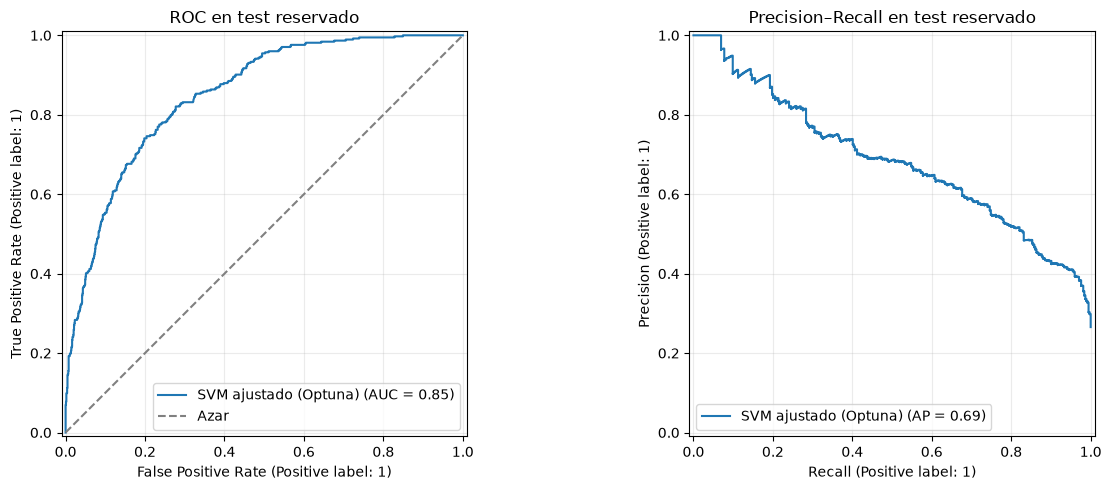

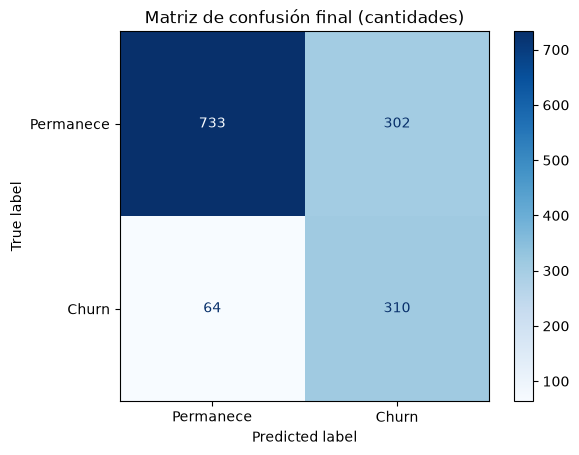

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
RocCurveDisplay.from_predictions(y_test, y_test_score, ax=axes[0], name=selected_name)
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Azar')
axes[0].set_title('ROC en test reservado')
axes[0].legend()
PrecisionRecallDisplay.from_predictions(y_test, y_test_score, ax=axes[1], name=selected_name)
axes[1].set_title('Precision–Recall en test reservado')
for ax in axes: ax.grid(alpha=0.25)
plt.tight_layout(); plt.savefig(FIGURES_DIR / '16_curvas_roc_precision_recall_test.png', dpi=180, bbox_inches='tight'); plt.show()
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Permanece', 'Churn']).plot(
    cmap='Blues', values_format='d')
plt.title('Matriz de confusión final (cantidades)'); plt.savefig(FIGURES_DIR / '17_matriz_confusion_test.png', dpi=180, bbox_inches='tight'); plt.show()

### Cierre de la sección 7: lectura de curvas y prioridad

En la ejecución vigente, ROC-AUC fue 85.13%, Recall 82.89% y Precision 50.65%. Hubo 310 verdaderos positivos, 64 falsos negativos, 302 falsos positivos y 733 verdaderos negativos. Las curvas y lift muestran el tradeoff de umbral, pero no determinan una política comercial por sí solos.


### Lectura adicional de lift y ganancia acumulada

El ranking utiliza el test reservado solo después de fijar el modelo. Mide cuántos abandonos históricos se concentran al revisar porcentajes superiores de clientes; no estima la efectividad de una campaña.


,Contactos aprox.,Churn capturados,Ganancia,Lift vs aleatorio
Top % clientes,,,,
10,141,109,0.291,2.912
20,282,193,0.516,2.578
30,423,253,0.676,2.253
50,705,323,0.864,1.726


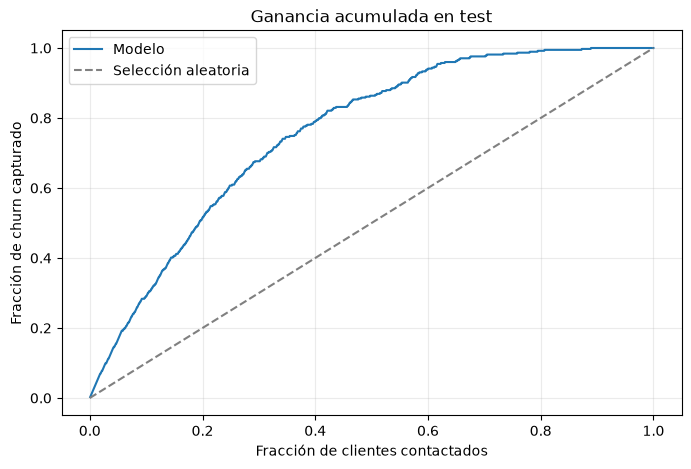

In [12]:
ranking = pd.DataFrame({'real': y_test.to_numpy(), 'score': np.asarray(y_test_score)})
ranking = ranking.sort_values('score', ascending=False).reset_index(drop=True)
total_churn = int(ranking['real'].sum())
summary_rows = []
for pct in (10, 20, 30, 50):
    n = max(1, int(np.ceil(len(ranking) * pct / 100)))
    captured = int(ranking.loc[:n-1, 'real'].sum())
    gain = captured / total_churn
    summary_rows.append({'Top % clientes': pct, 'Contactos aprox.': n,
        'Churn capturados': captured, 'Ganancia': gain,
        'Lift vs aleatorio': gain / (n / len(ranking))})
display(pd.DataFrame(summary_rows).set_index('Top % clientes').round(3))
ranking['fraccion_cartera'] = (np.arange(1, len(ranking)+1) / len(ranking))
ranking['ganancia'] = ranking['real'].cumsum() / total_churn
plt.figure(figsize=(8, 5))
plt.plot(ranking['fraccion_cartera'], ranking['ganancia'], label='Modelo')
plt.plot([0, 1], [0, 1], '--', color='gray', label='Selección aleatoria')
plt.xlabel('Fracción de clientes contactados'); plt.ylabel('Fracción de churn capturado')
plt.title('Ganancia acumulada en test'); plt.grid(alpha=0.25); plt.legend(); plt.savefig(FIGURES_DIR / '18_ganancia_acumulada_test.png', dpi=180, bbox_inches='tight'); plt.show()

### Cierre de la sección 7: alcance de la priorización

El ranking usa el `decision_function` del SVM lineal balanceado sin SMOTE. Las tablas de contactos sirven para discutir capacidad de campaña, no para demostrar causalidad ni retención conseguida.


## 8. Interpretabilidad por permutación y SHAP

Se permutan variables en un holdout explicativo interno de entrenamiento y se mide cuánto cambia el Recall del pipeline. Después, SHAP aproxima cómo el score de decisión cambia para casos de entrenamiento. Ambas técnicas son descriptivas y no usan test ni prueban causalidad.


,Predictor transformado,Caída media de Recall,Desviación
0,power__TotalCharges,0.1145,0.0048
6,categorical__Contract_Month-to-month,0.1033,0.0042
2,standard__MonthlyCharges,0.0460,0.0151
7,categorical__Contract_Two year,0.0146,0.0063
5,categorical__OnlineSecurity_No,0.0123,0.0042
1,standard__tenure,0.0000,0.0048
4,categorical__InternetService_Fiber optic,-0.0079,0.0042
3,categorical__MultipleLines_No,-0.0090,0.0032
8,categorical__PaperlessBilling_No,-0.0090,0.0042
9,categorical__PaymentMethod_Electronic check,-0.0090,0.0057


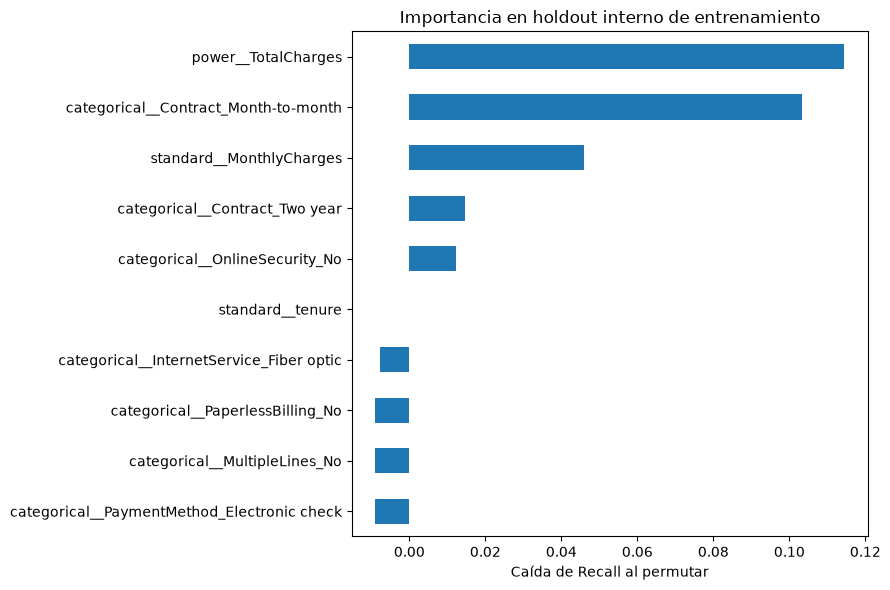

In [13]:
# Holdout interno de train únicamente para explicar; test no se consulta.
X_fit_explain, X_explain, y_fit_explain, y_explain = train_test_split(
    selected_train_features, y_train, test_size=0.2, random_state=RANDOM_STATE + 1, stratify=y_train)
explanation_pipeline = build_processed_evaluation_pipeline(
    clone(selected_classifier), use_smote=selected_smote, random_state=RANDOM_STATE)
explanation_pipeline.fit(X_fit_explain, y_fit_explain)
importance = permutation_importance(explanation_pipeline, X_explain, y_explain,
    scoring='recall', n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
importance_df = pd.DataFrame({'Predictor transformado': X_explain.columns,
    'Caída media de Recall': importance.importances_mean,
    'Desviación': importance.importances_std}).sort_values('Caída media de Recall', ascending=False)
display(importance_df.head(15).round(4))
ax = importance_df.head(15).sort_values('Caída media de Recall').plot.barh(
    x='Predictor transformado', y='Caída media de Recall', legend=False, figsize=(9, 6))
ax.set_xlabel('Caída de Recall al permutar'); ax.set_ylabel('')
ax.set_title('Importancia en holdout interno de entrenamiento'); plt.tight_layout(); plt.savefig(FIGURES_DIR / '19_importancia_permutacion_train.png', dpi=180, bbox_inches='tight'); plt.show()

### Cierre de la sección 8: importancia descriptiva

Las mayores caídas medias de Recall al permutar fueron `TotalCharges` (**0,1336**), `Contract` (**0,1302**) e `InternetService` (**0,0932**); `MonthlyCharges` produjo **0,0180**. Esto indica dependencia predictiva del pipeline en este holdout explicativo, no un efecto de negocio ni una jerarquía universal. Predictores correlacionados pueden compartir información, por lo que la importancia individual puede repartirse entre ellos.


### Alcance de SHAP

SHAP aproxima cómo las variables transformadas desplazan el score de decisión del SVM para casos de entrenamiento. Describe asociación predictiva, no causalidad, y no genera una probabilidad calibrada.


  0%|          | 0/3 [00:00<?, ?it/s]

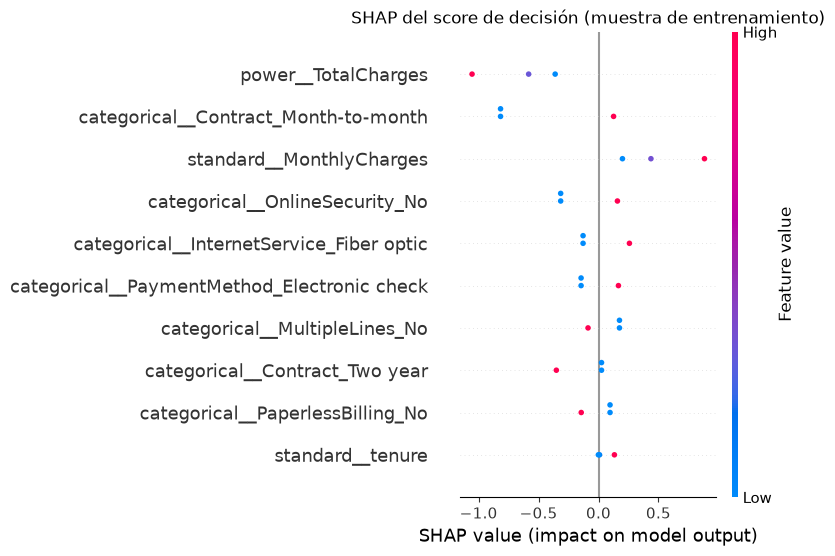

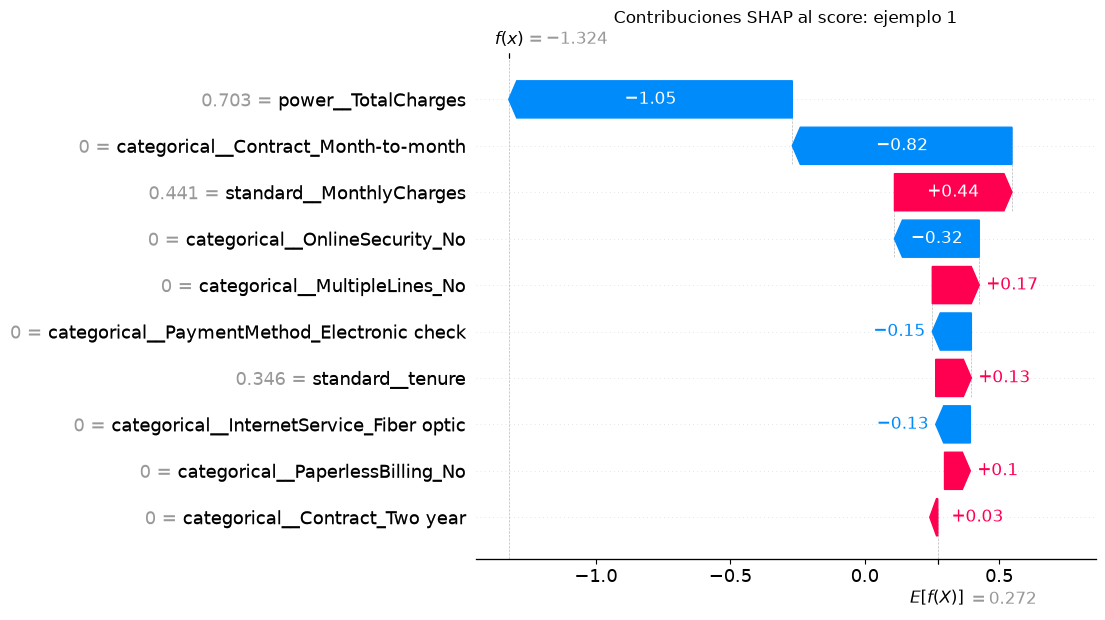

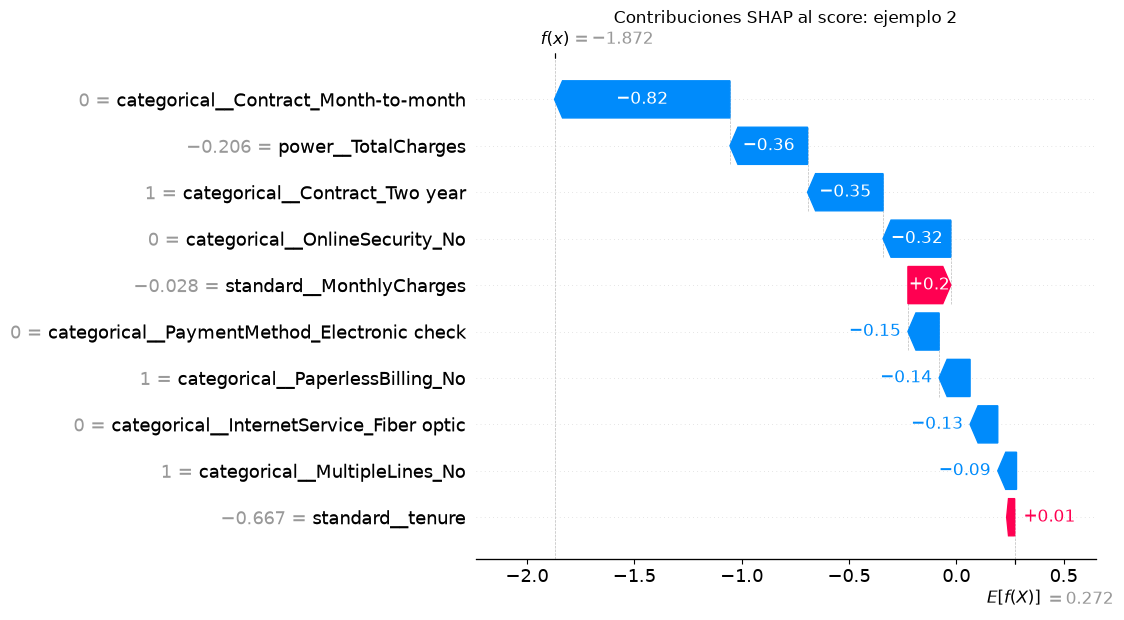

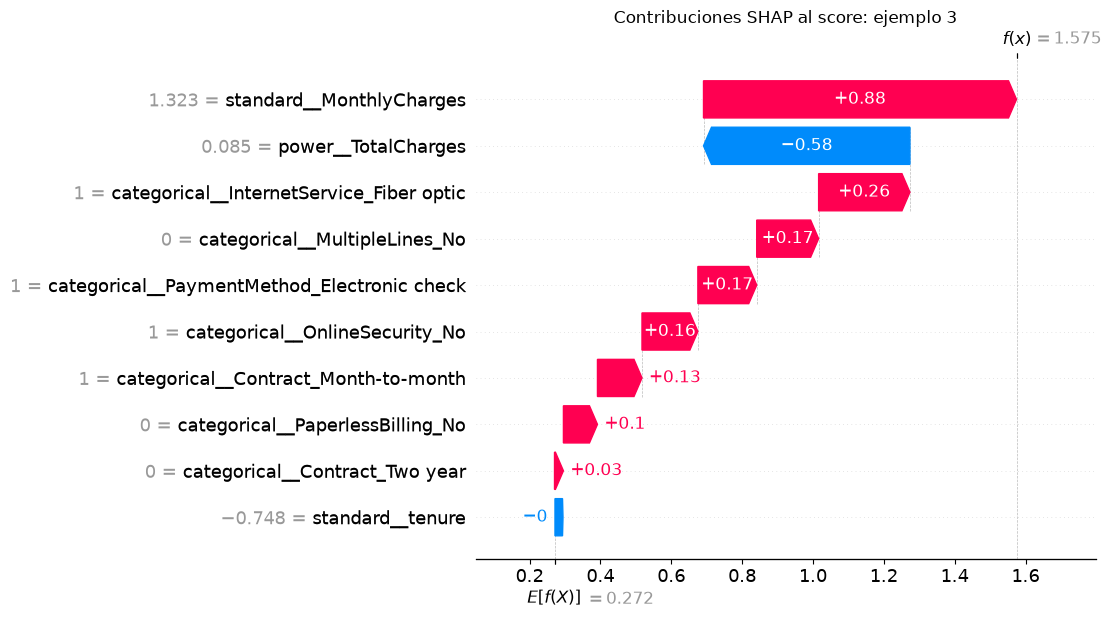

In [14]:
import shap

background = X_fit_explain.sample(
    n=min(15, len(X_fit_explain)), random_state=RANDOM_STATE,
)
X_shap = X_explain.iloc[:min(3, len(X_explain))].copy()

def score_for_shap(values):
    frame = pd.DataFrame(values, columns=selected_train_features.columns)
    for column in selected_train_features.columns:
        frame[column] = frame[column].astype(selected_train_features[column].dtype)
    return final_pipeline.decision_function(frame)

explainer = shap.KernelExplainer(
    score_for_shap, background.to_numpy(), feature_names=list(selected_train_features.columns),
)
shap_values = explainer.shap_values(X_shap.to_numpy(), nsamples=60)
shap_values = np.asarray(shap_values)
if shap_values.ndim == 3:
    shap_values = shap_values[..., 0]

shap.summary_plot(shap_values, X_shap, show=False, max_display=15)
plt.title('SHAP del score de decisión (muestra de entrenamiento)')
plt.savefig(FIGURES_DIR / '20_shap_summary_score_train.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close()

base_value = float(np.asarray(explainer.expected_value).reshape(-1)[0])
for row_index in range(len(X_shap)):
    explanation = shap.Explanation(
        values=shap_values[row_index],
        base_values=base_value,
        data=X_shap.iloc[row_index].to_numpy(),
        feature_names=list(X_shap.columns),
    )
    shap.plots.waterfall(explanation, max_display=12, show=False)
    plt.title(f'Contribuciones SHAP al score: ejemplo {row_index + 1}')
    plt.savefig(FIGURES_DIR / f'21_shap_waterfall_train_{row_index + 1}.png', dpi=180, bbox_inches='tight')
    plt.show()
    plt.close()

### Cierre de las explicaciones SHAP

Los gráficos descomponen el score del SVM para los ejemplos de entrenamiento y ayudan a revisar qué variables lo desplazan. La lectura coincide en términos generales con la permutación —`TotalCharges`, `Contract` e `InternetService` destacan—, aunque SHAP explica casos individuales y la permutación mide una caída promedio de Recall. Ninguna medida prueba causalidad, beneficio comercial ni una probabilidad individual de abandono.


## 9. Conclusiones vigentes

- **Test vigente:** 1.409 clientes y 374 abandonos reales.
- **Matriz del clasificador por defecto:** TN 733, FP 302, FN 64, TP 310.
- **Desempeño:** Accuracy 74.02%, Precision 50.65%, Recall 82.89%, F1 62.88%, ROC-AUC 85.13%.
- **Interpretabilidad:** permutación y SHAP describen asociación predictiva, no causalidad.
- **Umbral provisional:** el cuantil 75 de scores OOF produjo 362 clientes seleccionados en test, con 229 TP y 133 FP.
- **Estado:** el umbral requiere validación externa antes de aprobación comercial.
- **Permanencia:** mes a mes y fibra concentran mayor falsa alerta; antigüedad larga reduce FP.
- **Impacto:** las métricas no prueban retención causal ni beneficio comercial real.


In [15]:
import joblib

canonical_artifact = joblib.load(PROJECT_ROOT / 'output' / 'modelos' / 'telco_churn_pipeline.joblib')
artifact_metadata = canonical_artifact['metadata']

print('Comprobación de sincronización del artefacto canónico')
print(f"Modelo: {artifact_metadata['model_name']}")
print(f"C vigente: {artifact_metadata['best_params']['C']:.16f}")
print(f"Umbral vigente: {artifact_metadata['operating_threshold']:.16f}")
print(f"Test: {artifact_metadata['test_customers']} clientes, {artifact_metadata['test_churn']} abandonos")
print(
    'Matriz por defecto: '
    f"TN={artifact_metadata['test_true_negative']}, "
    f"FP={artifact_metadata['test_false_positive']}, "
    f"FN={artifact_metadata['test_false_negative']}, "
    f"TP={artifact_metadata['test_true_positive']}"
)
print(
    'Umbral provisional: '
    f"seleccionados={artifact_metadata['test_selected_count']}, "
    f"TP={artifact_metadata['test_threshold_true_positive']}, "
    f"FP={artifact_metadata['test_threshold_false_positive']}"
)

assert artifact_metadata['test_customers'] == 1409
assert artifact_metadata['test_churn'] == 374
assert artifact_metadata['test_true_negative'] == 733
assert artifact_metadata['test_false_positive'] == 302
assert artifact_metadata['test_false_negative'] == 64
assert artifact_metadata['test_true_positive'] == 310
assert abs(artifact_metadata['operating_threshold'] - 0.7245316291913046) < 1e-12
assert artifact_metadata['test_selected_count'] == 362
assert artifact_metadata['test_threshold_true_positive'] == 229
assert artifact_metadata['test_threshold_false_positive'] == 133
print('Sincronización verificable: OK')

Comprobación de sincronización del artefacto canónico
Modelo: SVM ajustado (Optuna)
C vigente: 0.1683454924600351
Umbral vigente: 0.7245316291913046
Test: 1409 clientes, 374 abandonos
Matriz por defecto: TN=733, FP=302, FN=64, TP=310
Umbral provisional: seleccionados=362, TP=229, FP=133
Sincronización verificable: OK
